In [ ]:
# Import Libraries
import pandas as pd # data analysis/manipulation
import numpy as np # numerical python/ calculation
import seaborn as sns #  visualization
import matplotlib.pyplot as plt #visualization

In [ ]:
from google.colab import files
uploaded_files = files.upload()
filename = next(iter(uploaded_files))
df = pd.read_csv(filename)
df.head()

Saving netflix_movies (1).csv to netflix_movies (1).csv


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [ ]:
df.tail()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
8802,s8803,Movie,Zodiac,David Fincher,"Mark Ruffalo, Jake Gyllenhaal, Robert Downey J...",United States,"November 20, 2019",2007,R,158 min,"Cult Movies, Dramas, Thrillers","A political cartoonist, a crime reporter and a..."
8803,s8804,TV Show,Zombie Dumb,NaN,NaN,NaN,"July 1, 2019",2018,TV-Y7,2 Seasons,"Kids' TV, Korean TV Shows, TV Comedies","While living alone in a spooky town, a young g..."
8804,s8805,Movie,Zombieland,Ruben Fleischer,"Jesse Eisenberg, Woody Harrelson, Emma Stone, ...",United States,"November 1, 2019",2009,R,88 min,"Comedies, Horror Movies",Looking to survive in a world taken over by zo...
8805,s8806,Movie,Zoom,Peter Hewitt,"Tim Allen, Courteney Cox, Chevy Chase, Kate Ma...",United States,"January 11, 2020",2006,PG,88 min,"Children & Family Movies, Comedies","Dragged from civilian life, a former superhero..."
8806,s8807,Movie,Zubaan,Mozez Singh,"Vicky Kaushal, Sarah-Jane Dias, Raaghav Chanan...",India,"March 2, 2019",2015,TV-14,111 min,"Dramas, International Movies, Music & Musicals",A scrappy but poor boy worms his way into a ty...


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
#df.drop_duplicates(inplace = True)(Removing Duplicate values)

In [ ]:
df.isnull().sum()

,0
show_id,0
type,0
title,0
director,2634
cast,825
country,831
date_added,10
release_year,0
rating,4
duration,3


In [ ]:
# Missing value Treatment
# Objective_Datatype_MODE
# Numerical_Datatype_Median/ Mean



In [ ]:
columns = ['director', 'cast', 'country', 'date_added', 'rating','duration']
for col in columns:
  df[col].fillna(df[col].mode()[0], inplace = True)


/tmp/ipykernel_500/2309879439.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].mode()[0], inplace = True)


In [ ]:

df.isnull().sum()

,0
show_id,0
type,0
title,0
director,0
cast,0
country,0
date_added,0
release_year,0
rating,0
duration,0


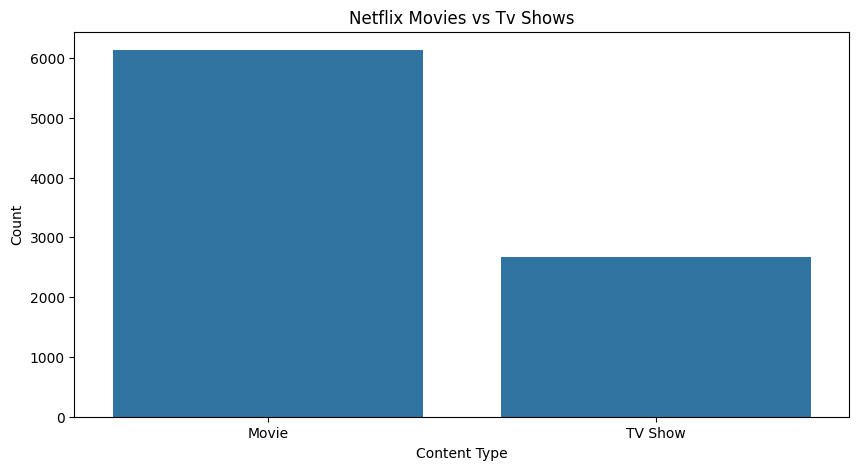

In [ ]:
# univariate Analysis:
plt.figure(figsize = (10,5))
sns.countplot(x="type",data = df)
plt.title("Netflix Movies vs Tv Shows")
plt.xlabel("Content Type")
plt.ylabel("Count")
plt.show()

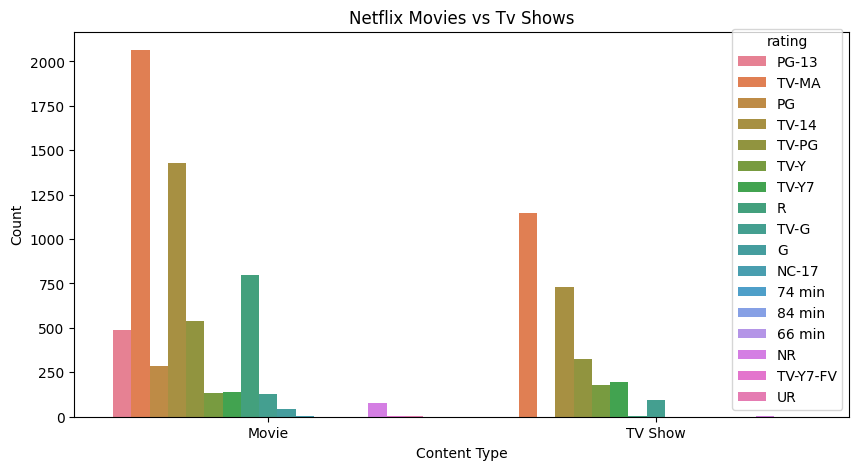

In [ ]:
# Bivariate Analysis
plt.figure(figsize = (10,5))
sns.countplot(x="type", hue = "rating", data = df)
plt.title("Netflix Movies vs Tv Shows")
plt.xlabel("Content Type")
plt.ylabel("Count")
plt.show()

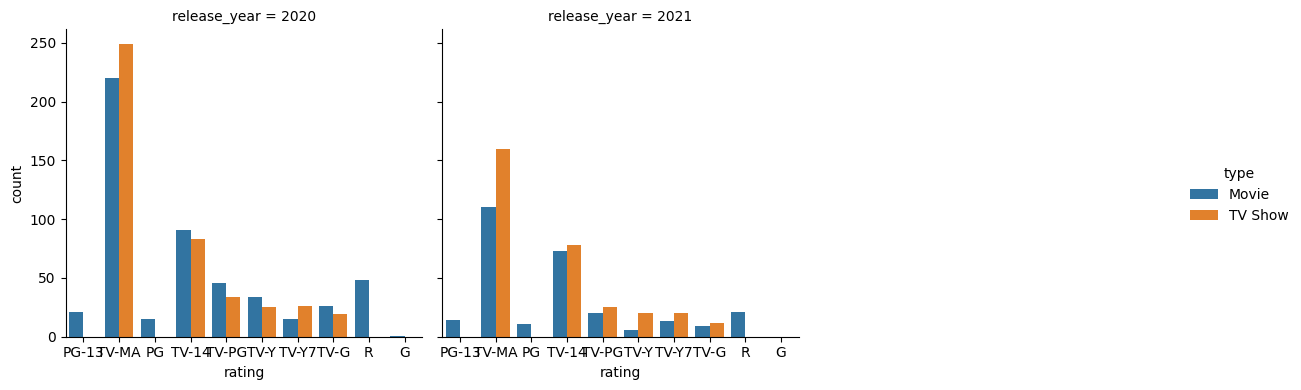

In [ ]:
# Multivariate
df_recent = df[df['release_year']>=2020]
sns.catplot(data = df_recent,x= 'rating',hue = 'type',col = 'release_year',kind = 'count',col_wrap =3, height = 4)
plt.show()


In [ ]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
for col in df.select_dtypes(include = 'object'):
  df[col] = le.fit_transform(df[col])

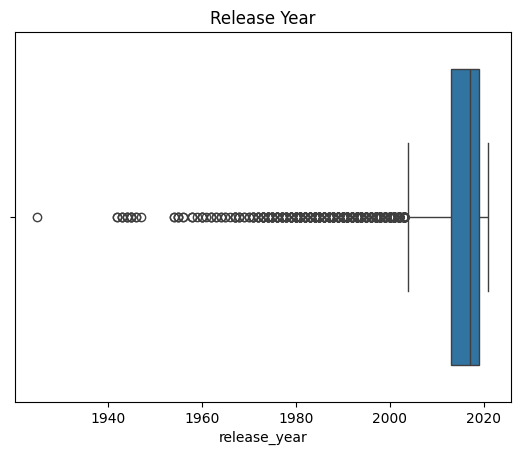

In [ ]:
# Outliers

sns.boxplot(x= df['release_year'])
plt.title("Release Year")
plt.show()

In [ ]:
# Outlier Treatment
Q1 = df['release_year'].quantile(0.25)
Q3 = df['release_year'].quantile(0.75)
IQR = Q3-Q1
lower = Q1 - 1.5*IQR
upper = Q3 + 1.5*IQR
df['release_year_capped'] = df['release_year'].clip(lower = lower, upper = upper)

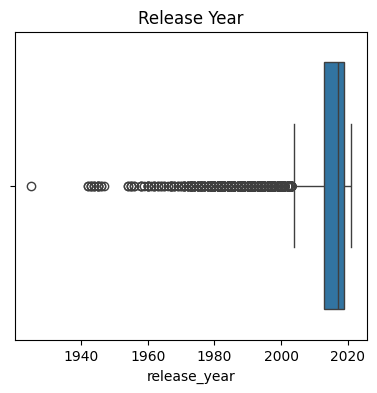

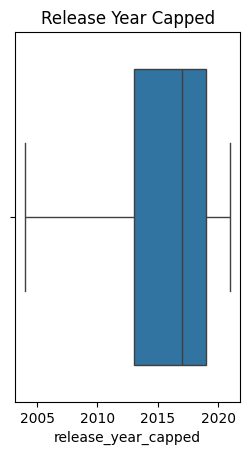

In [ ]:
plt.figure(figsize = (10,4))
plt.subplot(1,2,1)
sns.boxplot(x = df['release_year'])
plt.title("Release Year")
plt.show()

plt.subplot(1,2,2)
sns.boxplot(x = df['release_year_capped'])
plt.title("Release Year Capped")
plt.show()

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   show_id              8807 non-null   int64
 1   type                 8807 non-null   int64
 2   title                8807 non-null   int64
 3   director             8807 non-null   int64
 4   cast                 8807 non-null   int64
 5   country              8807 non-null   int64
 6   date_added           8807 non-null   int64
 7   release_year         8807 non-null   int64
 8   rating               8807 non-null   int64
 9   duration             8807 non-null   int64
 10  listed_in            8807 non-null   int64
 11  description          8807 non-null   int64
 12  release_year_capped  8807 non-null   int64
dtypes: int64(13)
memory usage: 894.6 KB


In [ ]:
import pickle
with open('netfilx_cleaned.pkl',"wb") as file:
  pickle.dump(df,file)
print("Dataset saved")

Dataset saved
